# Rubin / Skyfield Satellite-Contamination Analysis — Updated Pipeline

This notebook is adapted for the simulation output produced after the recent contamination-pipeline changes.

The updated simulation now:
- tracks only targets assigned to each OpSim visit,
- updates target positions at every sampled time,
- detects contamination from relative satellite–target segment geometry,
- records minimum separation and closest-approach fraction,
- evaluates sunlight at the interpolated contamination time,
- computes brightness only for contamination events when available,
- records contaminating-satellite identity and event-time metadata.

The notebook intentionally treats geometric contamination and sunlit/bright contamination as separate concepts. Shadowed events are retained rather than discarded.

## 1. Configuration

Edit only the paths in this cell for a new run. The loader discovers FITS files automatically, so there is no hand-written month list.

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.table import Table
from astropy.coordinates import SkyCoord
from astropy import units as u
from astropy.time import Time

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

PROJECT_ROOT = Path("/data/a.saricaoglu/repo/RubinsForge")

SIM_DIR = PROJECT_ROOT / "Skyfield/files/cont_improvement_satchecker_final"

OPSIM_EXPOSURES_FILE = (
    PROJECT_ROOT / "OpSim/scripts/twilight_visits_july2026.fits"
)

TARGET_CATALOG_FILE = PROJECT_ROOT / "in_LSST_footprint_coordinates.fits"

ANALYSIS_DIR = SIM_DIR / "analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

CONTAMINATION_THRESHOLD_ARCSEC = 67.5
DUPLICATE_TIME_TOLERANCE_S = 0.25

print("SIM_DIR:", SIM_DIR)
print("ANALYSIS_DIR:", ANALYSIS_DIR)

SIM_DIR: /data/a.saricaoglu/repo/RubinsForge/Skyfield/files/cont_improvement_satchecker_final
ANALYSIS_DIR: /data/a.saricaoglu/repo/RubinsForge/Skyfield/files/cont_improvement_satchecker_final/analysis


## 2. Robust FITS reader for the new output structure

Each simulation file can contain repeated groups of:
- `VISIT_INFO`
- `SATELLITE_DATA`
- `CONTAMINATED_TARGETS`
- `SEPARATIONS`

The functions below read all extensions in one pass and return tidy DataFrames. Missing optional columns are tolerated.

In [2]:
def snake_case(name):
    """Convert FITS column names to stable lowercase snake_case."""
    name = str(name).strip()
    name = re.sub(r"(?<=[a-z0-9])(?=[A-Z])", "_", name)
    name = re.sub(r"[^0-9A-Za-z]+", "_", name)
    return name.strip("_").lower()


def decode_object_columns(df):
    """Decode FITS byte strings without touching numeric columns."""
    out = df.copy()
    for col in out.select_dtypes(include=["object"]).columns:
        out[col] = out[col].map(
            lambda x: x.decode(errors="ignore").strip()
            if isinstance(x, (bytes, bytearray))
            else x
        )
    return out


def hdu_to_dataframe(hdu):
    """Convert a BinTableHDU into a pandas DataFrame."""
    if hdu.data is None:
        return pd.DataFrame()

    table = Table(hdu.data)
    try:
        df = table.to_pandas()
    except Exception:
        df = pd.DataFrame({
            name: np.asarray(table[name]).tolist()
            for name in table.colnames
        })

    df = decode_object_columns(df)
    df.columns = [snake_case(c) for c in df.columns]
    return df


def normalize_time_column(series):
    """
    Convert FITS/Astropy time columns into UTC pandas datetimes.

    Handles:
    - ISO-like strings,
    - scalar JD / MJD values,
    - Astropy FITS two-part JD values stored per row as [jd1, jd2].

    The last case is important because Astropy Time columns written to FITS
    are often represented internally as a two-element floating-point vector.
    """

    def parse_one(value):
        if value is None:
            return pd.NaT

        # Pandas / numpy missing values.
        try:
            if np.isscalar(value) and pd.isna(value):
                return pd.NaT
        except Exception:
            pass

        # Astropy FITS Time columns are commonly stored as [jd1, jd2].
        if isinstance(value, (list, tuple, np.ndarray)):
            arr = np.asarray(value).ravel()

            if arr.size == 0:
                return pd.NaT

            if arr.size == 1:
                return parse_one(arr[0])

            # Two-part Julian Date representation.
            try:
                vals = arr.astype(float)
                if vals.size == 2 and np.all(np.isfinite(vals)):
                    jd = float(vals[0] + vals[1])

                    if jd > 2_000_000:
                        return pd.Timestamp(
                            Time(jd, format="jd", scale="utc").to_datetime(
                                timezone=None
                            )
                        ).tz_localize("UTC")

                    if jd > 30_000:
                        return pd.Timestamp(
                            Time(jd, format="mjd", scale="utc").to_datetime(
                                timezone=None
                            )
                        ).tz_localize("UTC")
            except Exception:
                pass

            # If it is some other vector representation, do not guess.
            return pd.NaT

        # Numeric scalar JD / MJD.
        if isinstance(value, (int, float, np.integer, np.floating)):
            try:
                x = float(value)
                if not np.isfinite(x):
                    return pd.NaT

                if x > 2_000_000:
                    return pd.Timestamp(
                        Time(x, format="jd", scale="utc").to_datetime(
                            timezone=None
                        )
                    ).tz_localize("UTC")

                if x > 30_000:
                    return pd.Timestamp(
                        Time(x, format="mjd", scale="utc").to_datetime(
                            timezone=None
                        )
                    ).tz_localize("UTC")
            except Exception:
                return pd.NaT

        # ISO-like strings or already datetime-like objects.
        try:
            return pd.to_datetime(value, utc=True, errors="coerce")
        except Exception:
            return pd.NaT

    return series.map(parse_one)
def attach_common_metadata(df, hdu, source_file, hdu_index):
    """Attach provenance and exposure identifiers from FITS headers."""
    if df.empty:
        return df

    out = df.copy()
    out["source_file"] = source_file.name
    out["source_path"] = str(source_file)
    out["hdu_index"] = hdu_index

    expid = hdu.header.get("EXPID")
    visitid = hdu.header.get("VISITID")

    if "exposure_id" not in out.columns and expid is not None:
        out["exposure_id"] = expid
    if "visit_id" not in out.columns:
        out["visit_id"] = visitid if visitid is not None else expid

    return out


def load_simulation_outputs(sim_dir=SIM_DIR, pattern="*.fits"):
    """
    Load all new-pipeline simulation FITS files.

    Returns a dict of DataFrames:
    visits, satellites, contaminations, separations, files.
    """
    files = sorted(Path(sim_dir).glob(pattern))
    if not files:
        raise FileNotFoundError(f"No FITS files found in {sim_dir}")

    buckets = {
        "visits": [],
        "satellites": [],
        "contaminations": [],
        "separations": [],
    }
    file_rows = []

    for file_path in files:
        file_info = {
            "source_file": file_path.name,
            "source_path": str(file_path),
            "n_hdus": np.nan,
            "n_visit_hdus": 0,
            "n_satellite_hdus": 0,
            "n_contamination_hdus": 0,
            "n_separation_hdus": 0,
            "read_error": None,
        }

        try:
            with fits.open(file_path, memmap=True) as hdul:
                file_info["n_hdus"] = len(hdul)

                for idx, hdu in enumerate(hdul[1:], start=1):
                    extname = str(hdu.header.get("EXTNAME", "")).upper().strip()
                    if not extname:
                        continue

                    df = hdu_to_dataframe(hdu)
                    if df.empty:
                        continue

                    df = attach_common_metadata(df, hdu, file_path, idx)

                    if extname == "VISIT_INFO":
                        buckets["visits"].append(df)
                        file_info["n_visit_hdus"] += 1
                    elif extname == "SATELLITE_DATA":
                        buckets["satellites"].append(df)
                        file_info["n_satellite_hdus"] += 1
                    elif extname == "CONTAMINATED_TARGETS":
                        buckets["contaminations"].append(df)
                        file_info["n_contamination_hdus"] += 1
                    elif extname == "SEPARATIONS":
                        buckets["separations"].append(df)
                        file_info["n_separation_hdus"] += 1

        except Exception as exc:
            file_info["read_error"] = repr(exc)
            warnings.warn(f"Could not read {file_path.name}: {exc}")

        file_rows.append(file_info)

    result = {
        key: pd.concat(parts, ignore_index=True, sort=False)
        if parts else pd.DataFrame()
        for key, parts in buckets.items()
    }
    result["files"] = pd.DataFrame(file_rows)

    for key in ("visits", "satellites", "contaminations"):
        df = result[key]
        for col in ("time", "event_time", "exp_start", "exp_end"):
            if col in df.columns:
                df[col] = normalize_time_column(df[col])

    if "sunlit" in result["contaminations"].columns:
        s = result["contaminations"]["sunlit"]
        if not pd.api.types.is_bool_dtype(s):
            result["contaminations"]["sunlit"] = (
                s.astype(str)
                 .str.strip()
                 .str.lower()
                 .map({"true": True, "false": False, "1": True, "0": False})
                 .astype("boolean")
            )

    return result

In [3]:
data = load_simulation_outputs()

visits_df = data["visits"]
satellite_df = data["satellites"]
contamination_df = data["contaminations"]
separations_df = data["separations"]
files_df = data["files"]

print("Files:", len(files_df))
print("Visit rows:", len(visits_df))
print("Satellite rows:", len(satellite_df))
print("Contamination rows:", len(contamination_df))
print("Separation rows:", len(separations_df))

display(files_df.head())

Files: 200
Visit rows: 27751
Satellite rows: 1348505
Contamination rows: 754
Separation rows: 1601


,source_file,source_path,n_hdus,n_visit_hdus,n_satellite_hdus,n_contamination_hdus,n_separation_hdus,read_error
0,skyfield_data_visit_2025-11-01.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,192,109,78,2,2,None
1,skyfield_data_visit_2025-11-02.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,186,115,70,0,0,None
2,skyfield_data_visit_2025-11-10.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,261,151,107,1,1,None
3,skyfield_data_visit_2025-11-11.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,434,246,181,3,3,None
4,skyfield_data_visit_2025-11-12.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,462,259,192,5,5,None


In [41]:
print(
    "finite SATELLITE_DATA magnitudes:",
    np.isfinite(
        pd.to_numeric(
            satellite_df["ab_magnitude"],
            errors="coerce",
        )
    ).sum(),
)

print(
    "finite CONTAMINATED_TARGETS magnitudes:",
    np.isfinite(
        pd.to_numeric(
            contamination_df["ab_magnitude"],
            errors="coerce",
        )
    ).sum(),
)

finite SATELLITE_DATA magnitudes: 343
finite CONTAMINATED_TARGETS magnitudes: 391


## 3. Schema and run-integrity checks

This replaces many manual debugging cells in the older notebook. It checks whether the new metadata are present and whether geometric quantities obey expected ranges.

In [42]:
def report_schema(df, name):
    print(f"\n{name}: {len(df):,} rows")
    print("Columns:")
    print(", ".join(df.columns) if len(df.columns) else "(none)")


for name, frame in [
    ("visits_df", visits_df),
    ("satellite_df", satellite_df),
    ("contamination_df", contamination_df),
    ("separations_df", separations_df),
]:
    report_schema(frame, name)


def validate_contamination_rows(df, threshold_arcsec=CONTAMINATION_THRESHOLD_ARCSEC):
    checks = {}

    if df.empty:
        return pd.Series({"n_rows": 0}, dtype=object)

    checks["n_rows"] = len(df)

    if "t_closest" in df.columns:
        x = pd.to_numeric(df["t_closest"], errors="coerce")
        checks["invalid_t_closest"] = int(((x < 0) | (x > 1)).fillna(False).sum())

    sep_col = next(
        (c for c in (
            "contaminated_separation_arcsec",
            "contamianted_separation_arcsec",
        ) if c in df.columns),
        None,
    )
    if sep_col is not None:
        sep = pd.to_numeric(df[sep_col], errors="coerce")
        checks["separation_above_threshold"] = int(
            (sep > threshold_arcsec + 1e-9).fillna(False).sum()
        )
        checks["min_separation_arcsec"] = float(sep.min())
        checks["max_separation_arcsec"] = float(sep.max())

    if {"time", "event_time"}.issubset(df.columns):
        valid = df["time"].notna() & df["event_time"].notna()
        if valid.any():
            dt_s = (
                df.loc[valid, "time"] - df.loc[valid, "event_time"]
            ).dt.total_seconds()
            checks["event_time_after_segment_end"] = int((dt_s < -1e-6).sum())
            checks["event_time_more_than_1p1s_before_end"] = int((dt_s > 1.1).sum())
            checks["event_offset_min_s"] = float(dt_s.min())
            checks["event_offset_max_s"] = float(dt_s.max())

    if "sunlit" in df.columns:
        checks["sunlit_true"] = int((df["sunlit"] == True).sum())
        checks["sunlit_false"] = int((df["sunlit"] == False).sum())
        checks["sunlit_missing"] = int(df["sunlit"].isna().sum())

    return pd.Series(checks, dtype=object)


validation = validate_contamination_rows(contamination_df)
display(validation.to_frame("value"))


visits_df: 27,751 rows
Columns:
visit_id, field_ra, field_dec, filter, exposure_time, num_exposures, seeing, sky_brightness, tle_snapshot, tle_snapshot_mjd, tle_snapshot_offset_h, exposure_id, exp_start, exp_end, exp_duration, field_alt, field_az, source_file, source_path, hdu_index

satellite_df: 1,348,505 rows
Columns:
time, satellite_name, azimuth, altitude, height, intensity, ab_magnitude, angular_velocity, source_file, source_path, hdu_index, exposure_id, visit_id

contamination_df: 754 rows
Columns:
target_name, time, target_alt, target_az, contaminating_satellite, sunlit, t_closest, event_time, contaminated_separation_arcsec, intensity, ab_magnitude, tle_quality, tle_age_event_h, source_file, source_path, hdu_index, exposure_id, visit_id

separations_df: 1,601 rows
Columns:
separation_arcsec, source_file, source_path, hdu_index, exposure_id, visit_id


,value
n_rows,754
invalid_t_closest,0
separation_above_threshold,0
min_separation_arcsec,0.250864
max_separation_arcsec,67.441998
event_time_after_segment_end,0
event_time_more_than_1p1s_before_end,0
event_offset_min_s,0.0
event_offset_max_s,1.000035
sunlit_true,391


## 4. Load the OpSim visit-target table

The updated simulation already limits each `TargetTracker` to targets belonging to the current visit. Therefore the old notebook's post-hoc “inside LSST FOV?” selection is no longer the primary contamination criterion.

The exposure file is now used to:
- verify each contaminated target belongs to that visit,
- attach target RA/Dec,
- attach observing conditions.

In [6]:
def load_opsim_targets(path=OPSIM_EXPOSURES_FILE):
    with fits.open(path, memmap=True) as hdul:
        df = Table(hdul[1].data).to_pandas()

    df = decode_object_columns(df)
    df.columns = [snake_case(c) for c in df.columns]

    if "target_id" in df.columns:
        df["target_id"] = df["target_id"].astype(str).str.strip()

    dedup_cols = [c for c in ("visit_id", "target_id") if c in df.columns]
    if dedup_cols:
        df = df.drop_duplicates(dedup_cols).reset_index(drop=True)

    return df


opsim_targets_df = load_opsim_targets()
print("OpSim visit-target rows:", len(opsim_targets_df))
print("Unique visits:", opsim_targets_df["visit_id"].nunique())
print("Unique targets:", opsim_targets_df["target_id"].nunique())
display(opsim_targets_df.head())

OpSim visit-target rows: 30508
Unique visits: 2757
Unique targets: 8271


,visit_id,mjd,chile_time,exposure_time,num_exposures,filter,field_ra,field_dec,target_id,target_ra,target_dec,five_sigma_depth,seeing,sky_brightness
0,125932,61223.975717,2026-07-02 19:25:01,30.0,1,y,150.04249,2.220729,target_0000,149.84070,2.11067,20.841618,2.360445,17.945601
1,125932,61223.975717,2026-07-02 19:25:01,30.0,1,y,150.04249,2.220729,target_0001,149.85618,2.11212,20.841618,2.360445,17.945601
2,125932,61223.975717,2026-07-02 19:25:01,30.0,1,y,150.04249,2.220729,target_0002,149.87958,2.04139,20.841618,2.360445,17.945601
3,125932,61223.975717,2026-07-02 19:25:01,30.0,1,y,150.04249,2.220729,target_0003,149.89480,2.10936,20.841618,2.360445,17.945601
4,125932,61223.975717,2026-07-02 19:25:01,30.0,1,y,150.04249,2.220729,target_0004,149.99875,2.06333,20.841618,2.360445,17.945601


In [7]:
def find_target_twilight_exposures(
    target_id,
    exposures_file=OPSIM_EXPOSURES_FILE,
    pattern="twilight_visits*.fits",
):
    """
    Search all twilight_visits FITS files in the same directory as exposures_file
    and return all rows where target_id matches.

    Returns a DataFrame containing matching rows with provenance columns:
    source_file, source_path, source_row_index.
    """
    exposures_dir = Path(exposures_file).parent
    files = sorted(exposures_dir.glob(pattern))

    if not files:
        raise FileNotFoundError(
            f"No files matching '{pattern}' found in {exposures_dir}"
        )

    target_id_str = str(target_id).strip()
    matches = []

    for file_path in files:
        with fits.open(file_path, memmap=True) as hdul:
            if len(hdul) < 2 or hdul[1].data is None:
                continue

            df = Table(hdul[1].data).to_pandas()

        df = decode_object_columns(df)
        df.columns = [snake_case(c) for c in df.columns]

        if "target_id" not in df.columns:
            continue

        local = df.copy()
        local["target_id"] = local["target_id"].astype(str).str.strip()

        hit = local[local["target_id"] == target_id_str].copy()
        if hit.empty:
            continue

        hit["source_file"] = file_path.name
        hit["source_path"] = str(file_path)
        hit["source_row_index"] = hit.index.astype(int)
        matches.append(hit)

    if not matches:
        return pd.DataFrame()

    out = pd.concat(matches, ignore_index=True, sort=False)

    # Normalize common time-like columns if present.
    for col in ("time", "exp_start", "exp_end"):
        if col in out.columns:
            out[col] = normalize_time_column(out[col])

    return out


# Example usage:
# target_exposures = find_target_twilight_exposures("12345")
# print("Matches:", len(target_exposures))
# display(target_exposures.head())

In [8]:
def enrich_contaminations(contamination_df, visits_df, opsim_targets_df):
    """Attach visit/target metadata without changing the event population."""
    if contamination_df.empty:
        return contamination_df.copy()

    out = contamination_df.copy()

    if "target_name" in out.columns:
        out["target_id"] = out["target_name"].astype(str).str.strip()

    if "visit_id" in out.columns:
        out["visit_id"] = pd.to_numeric(out["visit_id"], errors="coerce").astype("Int64")

    if {"visit_id", "target_id"}.issubset(out.columns) and {
        "visit_id", "target_id"
    }.issubset(opsim_targets_df.columns):
        meta = opsim_targets_df.copy()
        meta["visit_id"] = pd.to_numeric(meta["visit_id"], errors="coerce").astype("Int64")
        keep = [
            c for c in (
                "visit_id", "target_id", "target_ra", "target_dec",
                "five_sigma_depth", "seeing", "sky_brightness",
                "filter", "field_ra", "field_dec", "mjd",
            )
            if c in meta.columns
        ]
        out = out.merge(
            meta[keep].drop_duplicates(["visit_id", "target_id"]),
            on=["visit_id", "target_id"],
            how="left",
            validate="many_to_one",
        )

    if not visits_df.empty and "visit_id" in visits_df.columns and "visit_id" in out.columns:
        visit_meta = visits_df.copy()
        visit_meta["visit_id"] = pd.to_numeric(
            visit_meta["visit_id"], errors="coerce"
        ).astype("Int64")
        visit_meta = visit_meta.drop_duplicates("visit_id")

        candidate_cols = [
            c for c in (
                "visit_id", "filter", "field_ra", "field_dec",
                "seeing", "sky_brightness", "exposure_time",
                "exp_start", "exp_end",
            )
            if c in visit_meta.columns and (c == "visit_id" or c not in out.columns)
        ]
        if len(candidate_cols) > 1:
            out = out.merge(
                visit_meta[candidate_cols],
                on="visit_id",
                how="left",
                validate="many_to_one",
            )

    return out


contamination_analysis_df = enrich_contaminations(
    contamination_df,
    visits_df,
    opsim_targets_df,
)

print("Enriched contamination rows:", len(contamination_analysis_df))
display(contamination_analysis_df.head())

Enriched contamination rows: 754


,target_name,time,target_alt,target_az,contaminating_satellite,sunlit,t_closest,event_time,contaminated_separation_arcsec,intensity,ab_magnitude,tle_quality,tle_age_event_h,source_file,source_path,hdu_index,exposure_id,visit_id,target_id,target_ra,target_dec,five_sigma_depth,seeing,sky_brightness,filter,field_ra,field_dec,mjd,exposure_time,exp_start,exp_end
0,target_3769,2025-11-02 01:21:30.265207+00:00,49.466479,131.125088,STARLINK-11354,False,0.701055,2025-11-02 01:21:29.966275+00:00,57.749496,NaN,NaN,fresh,5.174300,skyfield_data_visit_2025-11-01.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,85,140,140,target_3769,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-02 01:19:52+00:00,2025-11-02 01:20:22+00:00
1,target_16914,2025-11-02 01:53:41.523531+00:00,69.895210,205.512981,STARLINK-11235,False,0.440062,2025-11-02 01:53:40.963566+00:00,35.092960,NaN,NaN,fresh,13.581685,skyfield_data_visit_2025-11-01.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,159,192,192,target_16914,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-02 01:52:15+00:00,2025-11-02 01:52:45+00:00
2,target_16845,2025-11-02 01:53:54.523501+00:00,68.628245,206.014904,STARLINK-32626,False,0.043582,2025-11-02 01:53:53.567078+00:00,18.051289,NaN,NaN,fresh,7.533995,skyfield_data_visit_2025-11-01.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,159,192,192,target_16845,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-02 01:52:15+00:00,2025-11-02 01:52:45+00:00
3,target_17761,2025-11-11 00:55:42.061736+00:00,49.742583,8.798128,STARLINK-5557,True,0.265500,2025-11-11 00:55:41.327240+00:00,3.065879,5.608313e-11,6.406009,fresh,3.780595,skyfield_data_visit_2025-11-10.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,74,829,829,target_17761,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-11 00:54:23+00:00,2025-11-11 00:54:53+00:00
4,target_4145,2025-11-11 07:21:10.562276+00:00,50.553696,230.710426,STARLINK-1448,False,0.715471,2025-11-11 07:21:10.277748+00:00,62.851462,NaN,NaN,fresh,1.005304,skyfield_data_visit_2025-11-11.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,84,1414,1414,target_4145,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-11 07:19:48+00:00,2025-11-11 07:20:18+00:00


In [9]:
if len(contamination_analysis_df):
    if {"target_ra", "target_dec"}.issubset(contamination_analysis_df.columns):
        missing_target_meta = contamination_analysis_df[
            contamination_analysis_df["target_ra"].isna()
            | contamination_analysis_df["target_dec"].isna()
        ]
        print(
            f"Contaminations not matched to the visit-target table: "
            f"{len(missing_target_meta)} / {len(contamination_analysis_df)}"
        )
        if len(missing_target_meta):
            display(
                missing_target_meta[
                    [c for c in ("visit_id", "target_id", "source_file") if c in missing_target_meta]
                ].head(20)
            )

Contaminations not matched to the visit-target table: 754 / 754


,visit_id,target_id,source_file
0,140,target_3769,skyfield_data_visit_2025-11-01.fits
1,192,target_16914,skyfield_data_visit_2025-11-01.fits
2,192,target_16845,skyfield_data_visit_2025-11-01.fits
3,829,target_17761,skyfield_data_visit_2025-11-10.fits
4,1414,target_4145,skyfield_data_visit_2025-11-11.fits
5,1653,target_17766,skyfield_data_visit_2025-11-11.fits
6,1703,target_17560,skyfield_data_visit_2025-11-11.fits
7,1890,target_5094,skyfield_data_visit_2025-11-12.fits
8,2055,target_17690,skyfield_data_visit_2025-11-12.fits
9,2057,target_17393,skyfield_data_visit_2025-11-12.fits


## 5. Event-level derived quantities

This section normalizes the new event fields and creates useful derived columns.

In [10]:
c = contamination_analysis_df.copy()

if "contamianted_separation_arcsec" in c.columns and "contaminated_separation_arcsec" not in c.columns:
    c = c.rename(columns={
        "contamianted_separation_arcsec": "contaminated_separation_arcsec"
    })

for col in (
    "t_closest",
    "contaminated_separation_arcsec",
    "intensity",
    "ab_magnitude",
    "target_alt",
    "target_az",
):
    if col in c.columns:
        c[col] = pd.to_numeric(c[col], errors="coerce")

if {"time", "event_time"}.issubset(c.columns):
    c["event_offset_s"] = (c["time"] - c["event_time"]).dt.total_seconds()

if "event_time" in c.columns:
    c["event_date"] = c["event_time"].dt.date
    c["event_month"] = c["event_time"].dt.to_period("M").astype(str)

if "ab_magnitude" in c.columns:
    c["has_brightness"] = np.isfinite(c["ab_magnitude"])
else:
    c["has_brightness"] = False

contamination_analysis_df = c

display(contamination_analysis_df.head())

/tmp/ipykernel_2982995/3018298502.py:24: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  c["event_month"] = c["event_time"].dt.to_period("M").astype(str)


,target_name,time,target_alt,target_az,contaminating_satellite,sunlit,t_closest,event_time,contaminated_separation_arcsec,intensity,ab_magnitude,tle_quality,tle_age_event_h,source_file,source_path,hdu_index,exposure_id,visit_id,target_id,target_ra,target_dec,five_sigma_depth,seeing,sky_brightness,filter,field_ra,field_dec,mjd,exposure_time,exp_start,exp_end,event_offset_s,event_date,event_month,has_brightness
0,target_3769,2025-11-02 01:21:30.265207+00:00,49.466479,131.125088,STARLINK-11354,False,0.701055,2025-11-02 01:21:29.966275+00:00,57.749496,NaN,NaN,fresh,5.174300,skyfield_data_visit_2025-11-01.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,85,140,140,target_3769,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-02 01:19:52+00:00,2025-11-02 01:20:22+00:00,0.298932,2025-11-02,2025-11,False
1,target_16914,2025-11-02 01:53:41.523531+00:00,69.895210,205.512981,STARLINK-11235,False,0.440062,2025-11-02 01:53:40.963566+00:00,35.092960,NaN,NaN,fresh,13.581685,skyfield_data_visit_2025-11-01.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,159,192,192,target_16914,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-02 01:52:15+00:00,2025-11-02 01:52:45+00:00,0.559965,2025-11-02,2025-11,False
2,target_16845,2025-11-02 01:53:54.523501+00:00,68.628245,206.014904,STARLINK-32626,False,0.043582,2025-11-02 01:53:53.567078+00:00,18.051289,NaN,NaN,fresh,7.533995,skyfield_data_visit_2025-11-01.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,159,192,192,target_16845,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-02 01:52:15+00:00,2025-11-02 01:52:45+00:00,0.956423,2025-11-02,2025-11,False
3,target_17761,2025-11-11 00:55:42.061736+00:00,49.742583,8.798128,STARLINK-5557,True,0.265500,2025-11-11 00:55:41.327240+00:00,3.065879,5.608313e-11,6.406009,fresh,3.780595,skyfield_data_visit_2025-11-10.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,74,829,829,target_17761,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-11 00:54:23+00:00,2025-11-11 00:54:53+00:00,0.734496,2025-11-11,2025-11,True
4,target_4145,2025-11-11 07:21:10.562276+00:00,50.553696,230.710426,STARLINK-1448,False,0.715471,2025-11-11 07:21:10.277748+00:00,62.851462,NaN,NaN,fresh,1.005304,skyfield_data_visit_2025-11-11.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,84,1414,1414,target_4145,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-11 07:19:48+00:00,2025-11-11 07:20:18+00:00,0.284528,2025-11-11,2025-11,False


## 6. Run summary

The old notebook mixed several populations. This summary keeps visit counts, satellite sample rows, and geometric contaminations separate.

In [11]:
def run_summary(visits_df, satellite_df, contamination_df, opsim_targets_df):
    rows = []

    simulated_visit_ids = (
        set(pd.to_numeric(visits_df["visit_id"], errors="coerce").dropna().astype(int))
        if "visit_id" in visits_df.columns else set()
    )
    all_opsim_visit_ids = (
        set(pd.to_numeric(opsim_targets_df["visit_id"], errors="coerce").dropna().astype(int))
        if "visit_id" in opsim_targets_df.columns else set()
    )
    contaminated_visit_ids = (
        set(pd.to_numeric(contamination_df["visit_id"], errors="coerce").dropna().astype(int))
        if "visit_id" in contamination_df.columns else set()
    )

    rows.append(("OpSim visits in exposure table", len(all_opsim_visit_ids)))
    rows.append(("Visits written to simulation output", len(simulated_visit_ids)))
    rows.append(("Visits with >=1 contamination", len(contaminated_visit_ids)))
    rows.append(("Satellite sample rows", len(satellite_df)))
    rows.append(("Geometric contamination rows", len(contamination_df)))

    if "target_id" in contamination_df.columns:
        rows.append(("Unique contaminated targets", contamination_df["target_id"].nunique()))

    if "contaminating_satellite" in contamination_df.columns:
        rows.append((
            "Unique contaminating satellites",
            contamination_df["contaminating_satellite"].nunique(),
        ))

    if "sunlit" in contamination_df.columns:
        rows.append(("Sunlit contaminations", int((contamination_df["sunlit"] == True).sum())))
        rows.append(("Shadowed contaminations", int((contamination_df["sunlit"] == False).sum())))

    if "has_brightness" in contamination_df.columns:
        rows.append(("Contaminations with brightness", int(contamination_df["has_brightness"].sum())))

    summary = pd.DataFrame(rows, columns=["metric", "value"])

    if all_opsim_visit_ids:
        n = len(contaminated_visit_ids)
        summary.loc[len(summary)] = [
            "Contaminated-visit fraction (%)",
            100 * n / len(all_opsim_visit_ids),
        ]

    return summary


summary_df = run_summary(
    visits_df,
    satellite_df,
    contamination_analysis_df,
    opsim_targets_df,
)
display(summary_df)

,metric,value
0,OpSim visits in exposure table,2.757000e+03
1,Visits written to simulation output,2.775100e+04
2,Visits with >=1 contamination,4.900000e+02
3,Satellite sample rows,1.348505e+06
4,Geometric contamination rows,7.540000e+02
5,Unique contaminated targets,6.420000e+02
6,Unique contaminating satellites,4.890000e+02
7,Sunlit contaminations,3.910000e+02
8,Shadowed contaminations,3.630000e+02
9,Contaminations with brightness,3.910000e+02


## 7. Daily / monthly summaries

In [12]:
def contamination_time_column(df):
    if "event_time" in df.columns and df["event_time"].notna().any():
        return "event_time"
    if "time" in df.columns and df["time"].notna().any():
        return "time"
    return None


def build_time_summary(df, freq="D"):
    if df.empty:
        return pd.DataFrame()

    time_col = contamination_time_column(df)
    if time_col is None:
        raise ValueError("No usable time column found.")

    x = df[df[time_col].notna()].copy()
    x["period"] = x[time_col].dt.to_period(freq).astype(str)

    agg = {
        "contamination_events": (time_col, "size"),
    }
    if "visit_id" in x.columns:
        agg["contaminated_visits"] = ("visit_id", "nunique")
    if "target_id" in x.columns:
        agg["unique_targets"] = ("target_id", "nunique")
    if "contaminating_satellite" in x.columns:
        agg["unique_satellites"] = ("contaminating_satellite", "nunique")
    if "contaminated_separation_arcsec" in x.columns:
        agg["minimum_separation_arcsec"] = (
            "contaminated_separation_arcsec", "min"
        )

    result = x.groupby("period").agg(**agg).reset_index()

    if "sunlit" in x.columns:
        sunlit = (
            x.assign(sunlit_event=x["sunlit"].fillna(False).astype(bool))
             .groupby("period")["sunlit_event"]
             .sum()
             .rename("sunlit_events")
             .reset_index()
        )
        result = result.merge(sunlit, on="period", how="left")
        result["shadowed_events"] = (
            result["contamination_events"] - result["sunlit_events"]
        )

    return result


daily_summary = build_time_summary(contamination_analysis_df, freq="D")
monthly_summary = build_time_summary(contamination_analysis_df, freq="M")

display(daily_summary.head())
display(monthly_summary)

/tmp/ipykernel_2982995/1633104192.py:18: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  x["period"] = x[time_col].dt.to_period(freq).astype(str)
/tmp/ipykernel_2982995/1633104192.py:18: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  x["period"] = x[time_col].dt.to_period(freq).astype(str)


,period,contamination_events,contaminated_visits,unique_targets,unique_satellites,minimum_separation_arcsec,sunlit_events,shadowed_events
0,2025-11-02,3,2,3,3,18.051289,0,3
1,2025-11-11,2,2,2,2,3.065879,1,1
2,2025-11-12,3,3,3,3,19.722196,0,3
3,2025-11-13,8,5,7,6,4.007754,4,4
4,2025-11-14,2,2,2,2,12.335189,1,1


,period,contamination_events,contaminated_visits,unique_targets,unique_satellites,minimum_separation_arcsec,sunlit_events,shadowed_events
0,2025-11,121,89,111,91,1.303259,42,79
1,2025-12,107,74,96,73,0.250864,40,67
2,2026-01,131,83,124,86,1.148819,79,52
3,2026-02,110,63,99,66,0.274601,71,39
4,2026-03,75,50,72,51,0.354856,31,44
5,2026-04,70,48,63,48,2.131408,36,34
6,2026-05,70,42,69,42,0.720113,36,34
7,2026-06,70,41,67,43,0.273319,56,14


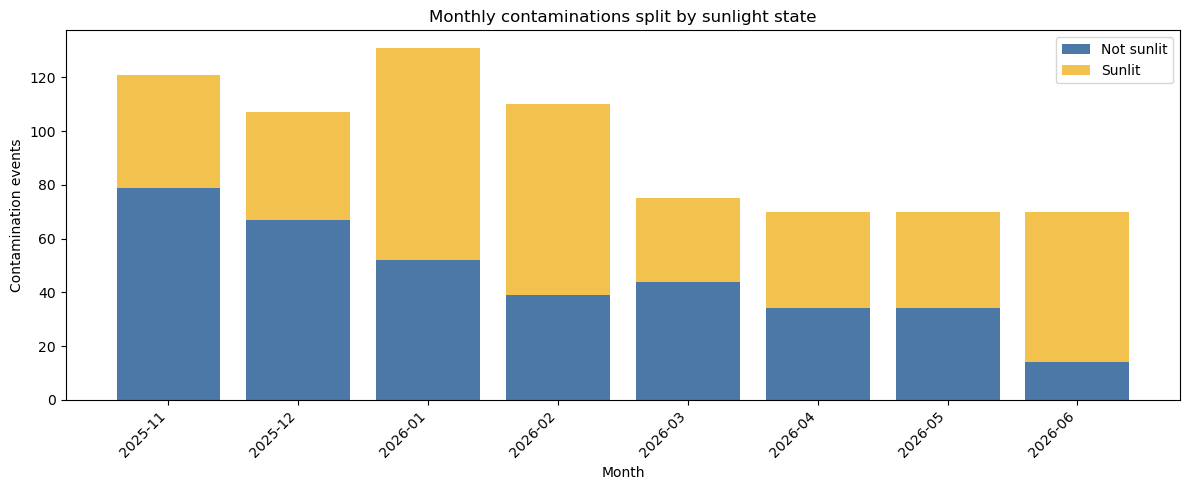

In [13]:
# Monthly stacked bar histogram: sunlit vs shadowed contaminations
# Uses the already-built monthly_summary table from section 7.
if monthly_summary.empty:
    print("No monthly contamination summary available.")
else:
    monthly_plot = monthly_summary.copy()
    if "period" not in monthly_plot.columns:
        raise KeyError("monthly_summary is missing the 'period' column.")

    # Normalize column names if the summary was built from an older notebook state.
    if "sunlit_events" not in monthly_plot.columns and "sunlit_contaminations" in monthly_plot.columns:
        monthly_plot = monthly_plot.rename(columns={"sunlit_contaminations": "sunlit_events"})
    if "shadowed_events" not in monthly_plot.columns and {"contamination_events", "sunlit_events"}.issubset(monthly_plot.columns):
        monthly_plot["shadowed_events"] = monthly_plot["contamination_events"] - monthly_plot["sunlit_events"]

    if {"sunlit_events", "shadowed_events"}.issubset(monthly_plot.columns):
        monthly_plot["sunlit_events"] = pd.to_numeric(monthly_plot["sunlit_events"], errors="coerce").fillna(0)
        monthly_plot["shadowed_events"] = pd.to_numeric(monthly_plot["shadowed_events"], errors="coerce").fillna(0)

        x = np.arange(len(monthly_plot))
        width = 0.8

        plt.figure(figsize=(12, 5))
        plt.bar(x, monthly_plot["shadowed_events"], width=width, label="Not sunlit", color="#4C78A8")
        plt.bar(
            x,
            monthly_plot["sunlit_events"],
            width=width,
            bottom=monthly_plot["shadowed_events"],
            label="Sunlit",
            color="#F2C14E",
        )

        plt.xticks(x, monthly_plot["period"], rotation=45, ha="right")
        plt.ylabel("Contamination events")
        plt.xlabel("Month")
        plt.title("Monthly contaminations split by sunlight state")
        plt.legend()
        plt.tight_layout()
        plt.show()
    else:
        print("monthly_summary does not include sunlit/shadowed contamination counts yet.")

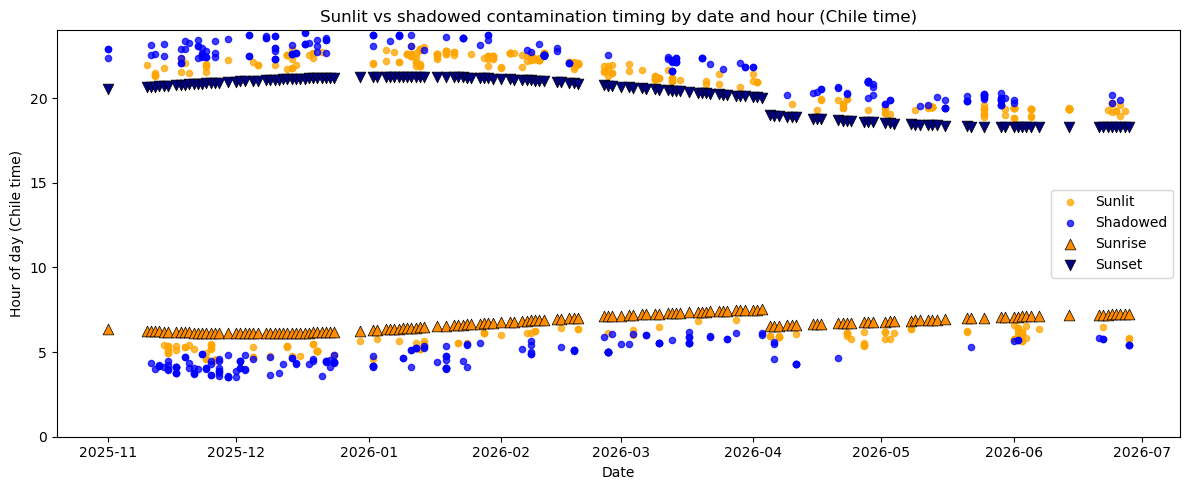

In [14]:
# Date-vs-hour scatter plot for contamination events
# x = local Chile date of the event, y = local Chile hour of day when it occurred
# Points are colored by whether the contamination was sunlit or shadowed.
# Sunrise/sunset markers are overlaid for each local Chile date.

if "event_time" in contamination_analysis_df.columns:
    plot_df = contamination_analysis_df[contamination_analysis_df["event_time"].notna()].copy()
    plot_df["sunlit_flag"] = plot_df["sunlit"].map({True: "Sunlit", False: "Shadowed"})

    event_dt = pd.to_datetime(plot_df["event_time"], utc=True).dt.tz_convert("America/Santiago")
    plot_df["event_date"] = event_dt.dt.date
    plot_df["event_hour"] = (
        event_dt.dt.hour
        + event_dt.dt.minute / 60.0
        + event_dt.dt.second / 3600.0
    )

    if not plot_df.empty:
        # Compute sunrise/sunset markers for each relevant Chile date.
        from skyfield.api import load, wgs84, S, W
        from zoneinfo import ZoneInfo

        eph = load("de421.bsp")
        earth = eph["earth"]
        sun = eph["sun"]
        ts = load.timescale()
        rubinobs = earth + wgs84.latlon(30.244633 * S, 70.749417 * W, elevation_m=2647)
        chile_tz = ZoneInfo("America/Santiago")

        def find_solar_crossing(date_value, rising=True, threshold_deg=-6.0):
            day = pd.Timestamp(date_value)
            day_start = ts.utc(day.year, day.month, day.day, 0, 0)
            day_end = ts.utc(day.year, day.month, day.day, 23, 59, 59)

            n_steps = 288  # 5-minute cadence across the whole day
            times = ts.linspace(day_start, day_end, n_steps)
            altitudes = []
            for t in times:
                alt, az, _ = rubinobs.at(t).observe(sun).apparent().altaz()
                altitudes.append(float(alt.degrees))

            altitudes = np.asarray(altitudes, dtype=float)
            if rising:
                hits = np.where((altitudes[:-1] < threshold_deg) & (altitudes[1:] >= threshold_deg))[0]
            else:
                hits = np.where((altitudes[:-1] >= threshold_deg) & (altitudes[1:] < threshold_deg))[0]

            if len(hits) == 0:
                return np.nan

            idx = int(hits[0])
            a0 = altitudes[idx]
            a1 = altitudes[idx + 1]
            t0 = times[idx]
            t1 = times[idx + 1]
            if np.isclose(a1, a0):
                return np.nan

            frac = (threshold_deg - a0) / (a1 - a0)
            crossing = t0 + (t1 - t0) * frac

            dt = pd.Timestamp(crossing.utc_datetime())
            if dt.tzinfo is None:
                dt = dt.tz_localize("UTC")
            dt_local = dt.tz_convert(chile_tz)
            hour = dt_local.hour + dt_local.minute / 60.0 + dt_local.second / 3600.0
            return hour

        dates = sorted(plot_df["event_date"].dropna().unique())
        sunrise_hours = []
        sunset_hours = []
        sunrise_dates = []
        sunset_dates = []

        for day in dates:
            rise = find_solar_crossing(day, rising=True, threshold_deg=-6.0)
            set_ = find_solar_crossing(day, rising=False, threshold_deg=-6.0)
            if np.isfinite(rise):
                sunrise_hours.append(float(rise))
                sunrise_dates.append(pd.Timestamp(day))
            if np.isfinite(set_):
                sunset_hours.append(float(set_))
                sunset_dates.append(pd.Timestamp(day))

        plt.figure(figsize=(12, 5))

        for label, mask, color in [
            ("Sunlit", plot_df["sunlit_flag"].eq("Sunlit"), 'orange'),
            ("Shadowed", plot_df["sunlit_flag"].eq("Shadowed"), 'blue'),
        ]:
            d = plot_df[mask]
            if d.empty:
                continue
            plt.scatter(
                d["event_date"],
                d["event_hour"],
                s=20,
                alpha=0.75,
                label=label,
                c=color
            )

        if sunrise_dates:
            plt.scatter(
                sunrise_dates,
                sunrise_hours,
                marker="^",
                s=60,
                color="darkorange",
                edgecolors="black",
                linewidths=0.5,
                label="Sunrise",
            )
        if sunset_dates:
            plt.scatter(
                sunset_dates,
                sunset_hours,
                marker="v",
                s=60,
                color="navy",
                edgecolors="black",
                linewidths=0.5,
                label="Sunset",
            )

        plt.xlabel("Date")
        plt.ylabel("Hour of day (Chile time)")
        plt.title("Sunlit vs shadowed contamination timing by date and hour (Chile time)")
        plt.ylim(0, 24)
        plt.legend()
        plt.tight_layout()
        plt.show()
    else:
        print("No contamination events with usable event times found.")
else:
    print("No 'event_time' column found; cannot plot date-vs-hour contamination timing.")


# The discontinuity at the start of April is due to daylight saving time in Chile. The local time jumps forward by one hour, so the hour-of-day values for events on that date will be offset by +1 hour compared to the previous day. 

## 8. Core diagnostic plots

These plots use only contamination-event quantities. The old generic separation histogram is kept separate because it describes a different population.

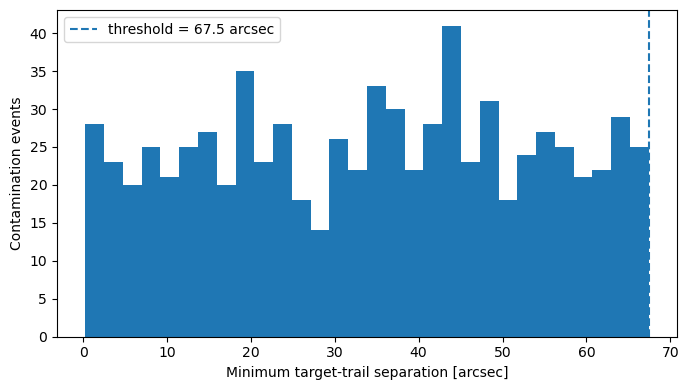

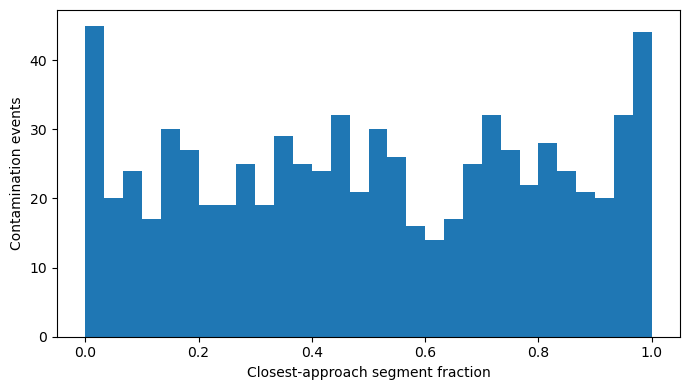

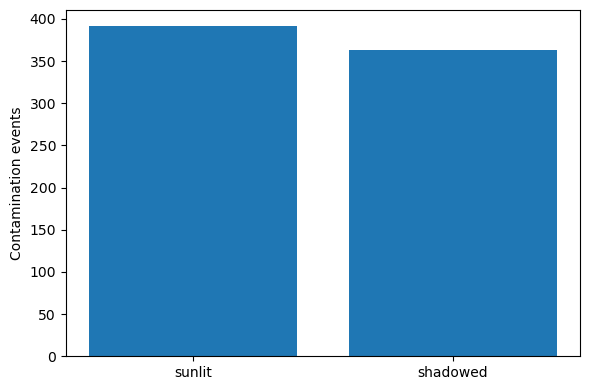

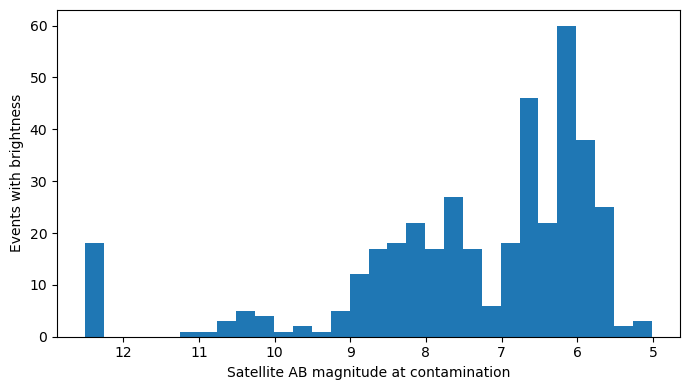

In [15]:
def plot_contamination_diagnostics(df):
    if df.empty:
        print("No contamination events to plot.")
        return

    if "contaminated_separation_arcsec" in df.columns:
        vals = df["contaminated_separation_arcsec"].dropna()
        if len(vals):
            plt.figure(figsize=(7, 4))
            plt.hist(vals, bins=30)
            plt.axvline(
                CONTAMINATION_THRESHOLD_ARCSEC,
                linestyle="--",
                label=f"threshold = {CONTAMINATION_THRESHOLD_ARCSEC:g} arcsec",
            )
            plt.xlabel("Minimum target-trail separation [arcsec]")
            plt.ylabel("Contamination events")
            plt.legend()
            plt.tight_layout()
            plt.show()

    if "t_closest" in df.columns:
        vals = df["t_closest"].dropna()
        if len(vals):
            plt.figure(figsize=(7, 4))
            plt.hist(vals, bins=np.linspace(0, 1, 31))
            plt.xlabel("Closest-approach segment fraction")
            plt.ylabel("Contamination events")
            plt.tight_layout()
            plt.show()

    if "sunlit" in df.columns:
        counts = df["sunlit"].value_counts(dropna=False)
        labels = [
            "sunlit" if k is True else "shadowed" if k is False else "missing"
            for k in counts.index
        ]
        plt.figure(figsize=(6, 4))
        plt.bar(labels, counts.values)
        plt.ylabel("Contamination events")
        plt.tight_layout()
        plt.show()

    if "ab_magnitude" in df.columns:
        vals = pd.to_numeric(df["ab_magnitude"], errors="coerce").dropna()
        if len(vals):
            plt.figure(figsize=(7, 4))
            plt.hist(vals, bins=30)
            plt.xlabel("Satellite AB magnitude at contamination")
            plt.ylabel("Events with brightness")
            plt.gca().invert_xaxis()
            plt.tight_layout()
            plt.show()


plot_contamination_diagnostics(contamination_analysis_df)

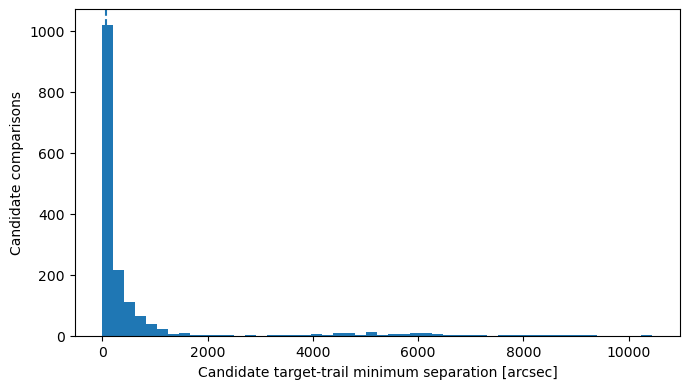

In [16]:
# Optional: all candidate/coarse-filter separations saved in SEPARATIONS HDUs.
# This is NOT the same population as contamination-event separations.
sep_col = "separation_arcsec" if "separation_arcsec" in separations_df.columns else None

if sep_col is not None and len(separations_df):
    vals = pd.to_numeric(separations_df[sep_col], errors="coerce").dropna()
    if len(vals):
        plt.figure(figsize=(7, 4))
        plt.hist(vals, bins=50)
        plt.axvline(CONTAMINATION_THRESHOLD_ARCSEC, linestyle="--")
        plt.xlabel("Candidate target-trail minimum separation [arcsec]")
        plt.ylabel("Candidate comparisons")
        plt.tight_layout()
        plt.show()

## 9. Duplicate-event audit

A target can in principle be detected in adjacent trail segments near a shared endpoint. This reports possible duplicates but removes nothing automatically.

In [17]:
def find_possible_duplicate_events(
    df,
    tolerance_s=DUPLICATE_TIME_TOLERANCE_S,
):
    required = {"visit_id", "target_id", "contaminating_satellite", "event_time"}
    if df.empty or not required.issubset(df.columns):
        return pd.DataFrame()

    x = df.dropna(subset=list(required)).copy()
    x = x.sort_values(
        ["visit_id", "target_id", "contaminating_satellite", "event_time"]
    )

    group_cols = ["visit_id", "target_id", "contaminating_satellite"]
    x["previous_event_time"] = x.groupby(group_cols)["event_time"].shift()
    x["delta_from_previous_event_s"] = (
        x["event_time"] - x["previous_event_time"]
    ).dt.total_seconds()

    return x[
        x["delta_from_previous_event_s"].between(
            0,
            tolerance_s,
            inclusive="both",
        )
    ]


possible_duplicates = find_possible_duplicate_events(contamination_analysis_df)
print("Possible adjacent duplicate events:", len(possible_duplicates))
display(possible_duplicates.head(20))

Possible adjacent duplicate events: 41


,target_name,time,target_alt,target_az,contaminating_satellite,sunlit,t_closest,event_time,contaminated_separation_arcsec,intensity,ab_magnitude,tle_quality,tle_age_event_h,source_file,source_path,hdu_index,exposure_id,visit_id,target_id,target_ra,target_dec,five_sigma_depth,seeing,sky_brightness,filter,field_ra,field_dec,mjd,exposure_time,exp_start,exp_end,event_offset_s,event_date,event_month,has_brightness,previous_event_time,delta_from_previous_event_s
14,target_2063,2025-11-13 07:12:22.193668+00:00,39.284131,237.340702,STARLINK-5463,False,0.027543,2025-11-13 07:12:21.221233+00:00,24.802418,NaN,NaN,fresh,3.075010,skyfield_data_visit_2025-11-13.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,67,2668,2668,target_2063,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-13 07:11:02+00:00,2025-11-13 07:11:32+00:00,0.972435,2025-11-13,2025-11,False,2025-11-13 07:12:21.193673+00:00,0.027560
26,target_3020,2025-11-15 07:58:21.270193+00:00,36.102104,222.062787,STARLINK-5069,True,0.000000,2025-11-15 07:58:20.270198+00:00,42.851594,7.984351e-12,8.522491,fresh,3.691413,skyfield_data_visit_2025-11-15.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,191,3930,3930,target_3020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-15 07:57:08+00:00,2025-11-15 07:57:38+00:00,0.999995,2025-11-15,2025-11,True,2025-11-15 07:58:20.237811+00:00,0.032387
47,target_2966,2025-11-19 07:42:12.522239+00:00,31.782903,248.794095,STARLINK-2251,False,0.033066,2025-11-19 07:42:11.555316+00:00,38.542311,NaN,NaN,fresh,3.655659,skyfield_data_visit_2025-11-19.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,140,5171,5171,target_2966,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-19 07:41:00+00:00,2025-11-19 07:41:30+00:00,0.966923,2025-11-19,2025-11,False,2025-11-19 07:42:11.522244+00:00,0.033072
49,target_5116,2025-11-19 08:19:28.217978+00:00,44.665158,216.336263,STARLINK-4510,True,0.000000,2025-11-19 08:19:27.217983+00:00,24.546200,1.204135e-11,8.076402,fresh,3.876676,skyfield_data_visit_2025-11-19.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,177,5211,5211,target_5116,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-19 08:17:54+00:00,2025-11-19 08:18:24+00:00,0.999995,2025-11-19,2025-11,True,2025-11-19 08:19:27.211747+00:00,0.006236
66,target_17750,2025-11-23 02:03:05.849337+00:00,60.316884,308.415840,STARLINK-30794,False,0.025127,2025-11-23 02:03:04.874488+00:00,9.371031,NaN,NaN,fresh,6.587136,skyfield_data_visit_2025-11-22.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,426,6995,6995,target_17750,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-23 02:01:38+00:00,2025-11-23 02:02:08+00:00,0.974849,2025-11-23,2025-11,False,2025-11-23 02:03:04.849343+00:00,0.025145
78,target_4424,2025-11-24 07:04:44.261169+00:00,47.155089,253.324142,STARLINK-11631,False,0.006978,2025-11-24 07:04:43.268134+00:00,51.625599,NaN,NaN,fresh,11.240226,skyfield_data_visit_2025-11-24.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,81,8123,8123,target_4424,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,38.0,2025-11-24 07:03:32+00:00,2025-11-24 07:04:10+00:00,0.993035,2025-11-24,2025-11,False,2025-11-24 07:04:43.261174+00:00,0.006960
80,target_4257,2025-11-24 07:35:43.974195+00:00,39.899770,213.494245,STARLINK-3208,True,0.008079,2025-11-24 07:35:42.982288+00:00,48.083197,1.212257e-11,8.069103,fresh,3.531055,skyfield_data_visit_2025-11-24.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,154,8166,8166,target_4257,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-24 07:34:32+00:00,2025-11-24 07:35:02+00:00,0.991907,2025-11-24,2025-11,True,2025-11-24 07:35:42.974201+00:00,0.008087
87,target_1318,2025-11-25 01:26:27.098680+00:00,44.718019,4.336693,STARLINK-6280,False,0.008956,2025-11-25 01:26:26.107658+00:00,46.035126,NaN,NaN,fresh,4.909701,skyfield_data_visit_2025-11-24.fits,/data/a.saricaoglu/repo/RubinsForge/Skyfield/f...,483,8351,8351,target_1318,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,2025-11-25 01:25:08+00:00,2025-11-25 01:25:38+00:00,0.991022,2025-11-25

## 10. Per-target and per-satellite contamination counts

In [18]:
if len(contamination_analysis_df):
    if "target_id" in contamination_analysis_df.columns:
        target_counts = (
            contamination_analysis_df
            .groupby("target_id", dropna=False)
            .agg(
                contamination_events=("target_id", "size"),
                contaminated_visits=("visit_id", "nunique"),
            )
            .sort_values("contamination_events", ascending=False)
            .reset_index()
        )
        display(target_counts.head(20))

    if "contaminating_satellite" in contamination_analysis_df.columns:
        agg = {
            "contamination_events": ("contaminating_satellite", "size"),
            "contaminated_visits": ("visit_id", "nunique"),
        }
        if "target_id" in contamination_analysis_df.columns:
            agg["unique_targets"] = ("target_id", "nunique")

        sat_counts = (
            contamination_analysis_df
            .groupby("contaminating_satellite", dropna=False)
            .agg(**agg)
            .sort_values("contamination_events", ascending=False)
            .reset_index()
        )
        display(sat_counts.head(20))

,target_id,contamination_events,contaminated_visits
0,target_3198,4,3
1,target_8510,4,3
2,target_3233,3,3
3,target_3130,3,3
4,target_8656,3,2
5,target_8712,3,3
6,target_8708,3,3
7,target_3144,3,2
8,target_1318,3,2
9,target_3164,3,3


,contaminating_satellite,contamination_events,contaminated_visits,unique_targets
0,STARLINK-34858,8,1,7
1,STARLINK-30300,8,2,8
2,STARLINK-34211,8,1,8
3,STARLINK-31452,7,1,7
4,STARLINK-31729,7,2,7
5,STARLINK-35693,6,1,5
6,STARLINK-36399,6,1,6
7,STARLINK-31083,6,1,6
8,STARLINK-3318,6,1,5
9,STARLINK-31958,5,1,5


## 11. Brightness analysis for contamination events

Brightness is intentionally evaluated only for relevant contamination events. Geometric events remain in the dataset even when shadowed or when brightness calculation fails.

In [19]:
def brightness_summary(df):
    if df.empty:
        return pd.DataFrame()

    x = df.copy()

    if "ab_magnitude" not in x.columns:
        raise KeyError(
            "No 'ab_magnitude' column found in the contamination data."
        )

    x["ab_magnitude"] = pd.to_numeric(
        x["ab_magnitude"],
        errors="coerce",
    )

    rows = []

    populations = {
        "all geometric contaminations": x,
    }

    if "sunlit" in x.columns:
        populations["sunlit"] = x[x["sunlit"] == True]
        populations["shadowed"] = x[x["sunlit"] == False]

    for label, y in populations.items():

        mags = y["ab_magnitude"].dropna()

        rows.append({
            "population": label,
            "n_events": len(y),
            "n_with_brightness": len(mags),

            "brightness_fraction": (
                len(mags) / len(y)
                if len(y) > 0
                else np.nan
            ),

            "median_ab_mag": (
                mags.median()
                if len(mags) > 0
                else np.nan
            ),

            "min_ab_mag_brightest": (
                mags.min()
                if len(mags) > 0
                else np.nan
            ),

            "max_ab_mag_faintest": (
                mags.max()
                if len(mags) > 0
                else np.nan
            ),
        })

    return pd.DataFrame(rows)


display(brightness_summary(contamination_analysis_df))

,population,n_events,n_with_brightness,brightness_fraction,median_ab_mag,min_ab_mag_brightest,max_ab_mag_faintest
0,all geometric contaminations,754,391,0.518568,6.733886,5.016647,12.5
1,sunlit,391,391,1.000000,6.733886,5.016647,12.5
2,shadowed,363,0,0.000000,NaN,NaN,NaN


In [20]:
print(contamination_analysis_df["ab_magnitude"].head(20))
print(
    "finite magnitudes:",
    np.isfinite(
        pd.to_numeric(
            contamination_analysis_df["ab_magnitude"],
            errors="coerce"
        )
    ).sum()
)

0          NaN
1          NaN
2          NaN
3     6.406009
4          NaN
5          NaN
6          NaN
7          NaN
8     5.741209
9     5.849908
10    5.823536
11    5.788761
12         NaN
13         NaN
14         NaN
15         NaN
16         NaN
17    6.148491
18    5.900842
19         NaN
Name: ab_magnitude, dtype: float64
finite magnitudes: 391


In [21]:
sunlit_events = contamination_analysis_df[
    contamination_analysis_df["sunlit"] == True
]

print("sunlit events:", len(sunlit_events))

print(
    sunlit_events[
        ["intensity", "ab_magnitude"]
    ]
)
print(
    "sunlit events with finite magnitude:",
    np.isfinite(
        pd.to_numeric(
            sunlit_events["ab_magnitude"],
            errors="coerce"
        )
    ).sum()
)

sunlit events: 391
        intensity  ab_magnitude
3    5.608313e-11      6.406009
8    1.034552e-10      5.741209
9    9.359932e-11      5.849908
10   9.590067e-11      5.823536
11   9.902195e-11      5.788761
..            ...           ...
745  6.642132e-11      6.222321
746  4.554966e-11      6.631877
748  5.185977e-11      6.491013
752  4.854623e-11      6.562701
753  7.608888e-11      6.074787

[391 rows x 2 columns]
sunlit events with finite magnitude: 391


In [22]:
satellite_df.loc[
    np.isfinite(satellite_df["ab_magnitude"]),
    [
        "visit_id",
        "time",
        "satellite_name",
        "intensity",
        "ab_magnitude",
    ],
].head(20)

,visit_id,time,satellite_name,intensity,ab_magnitude
10422,829,2025-11-11 00:55:42.061736+00:00,STARLINK-5557,5.608313e-11,6.406009
28622,2055,2025-11-13 00:19:55.071933+00:00,STARLINK-32386,1.034552e-10,5.741209
28759,2057,2025-11-13 00:21:21.321032+00:00,STARLINK-32436,9.359932e-11,5.849908
28760,2057,2025-11-13 00:21:22.321027+00:00,STARLINK-32436,9.590067e-11,5.823536
29053,2068,2025-11-13 00:27:47.770877+00:00,STARLINK-33567,9.902195e-11,5.788761
42699,3244,2025-11-14 08:23:56.487173+00:00,STARLINK-11313,7.109507e-11,6.148491
44679,3335,2025-11-15 00:46:09.731829+00:00,STARLINK-34516,8.930979e-11,5.900842
55207,3930,2025-11-15 07:58:20.270198+00:00,STARLINK-5069,7.973964e-12,8.523904
55208,3930,2025-11-15 07:58:21.270193+00:00,STARLINK-5069,7.984351e-12,8.522491
55473,3936,2025-11-15 08:02:16.489798+00:00,STARLINK-31389,1.594679e-11,7.771407


In [23]:
sunlit_events = contamination_analysis_df[
    contamination_analysis_df["sunlit"] == True
]

np.isfinite(
    pd.to_numeric(
        sunlit_events["ab_magnitude"],
        errors="coerce",
    )
).sum()

np.int64(391)

In [24]:
contamination_analysis_df.columns.tolist()

['target_name',
 'time',
 'target_alt',
 'target_az',
 'contaminating_satellite',
 'sunlit',
 't_closest',
 'event_time',
 'contaminated_separation_arcsec',
 'intensity',
 'ab_magnitude',
 'tle_quality',
 'tle_age_event_h',
 'source_file',
 'source_path',
 'hdu_index',
 'exposure_id',
 'visit_id',
 'target_id',
 'target_ra',
 'target_dec',
 'five_sigma_depth',
 'seeing',
 'sky_brightness',
 'filter',
 'field_ra',
 'field_dec',
 'mjd',
 'exposure_time',
 'exp_start',
 'exp_end',
 'event_offset_s',
 'event_date',
 'event_month',
 'has_brightness']

## 12. Visit-level contamination table

In [25]:
def build_visit_summary(visits_df, satellite_df, contamination_df):
    ids = set()

    for df in (visits_df, satellite_df, contamination_df):
        if not df.empty and "visit_id" in df.columns:
            ids.update(
                pd.to_numeric(df["visit_id"], errors="coerce")
                .dropna()
                .astype(int)
                .tolist()
            )

    result = pd.DataFrame({"visit_id": sorted(ids)})

    if not visits_df.empty and "visit_id" in visits_df.columns:
        vm = visits_df.copy()
        vm["visit_id"] = pd.to_numeric(vm["visit_id"], errors="coerce").astype("Int64")
        vm = vm.drop_duplicates("visit_id")
        keep = [
            c for c in (
                "visit_id", "filter", "field_ra", "field_dec",
                "seeing", "sky_brightness", "exposure_time",
                "exp_start", "exp_end",
            )
            if c in vm.columns
        ]
        result = result.merge(vm[keep], on="visit_id", how="left")

    if not satellite_df.empty and "visit_id" in satellite_df.columns:
        agg = {"satellite_samples": ("visit_id", "size")}
        if "satellite_name" in satellite_df.columns:
            agg["unique_sampled_satellites"] = ("satellite_name", "nunique")
        s = satellite_df.groupby("visit_id").agg(**agg).reset_index()
        result = result.merge(s, on="visit_id", how="left")

    if not contamination_df.empty and "visit_id" in contamination_df.columns:
        agg = {"contamination_events": ("visit_id", "size")}
        if "target_id" in contamination_df.columns:
            agg["unique_contaminated_targets"] = ("target_id", "nunique")
        if "contaminating_satellite" in contamination_df.columns:
            agg["unique_contaminating_satellites"] = (
                "contaminating_satellite", "nunique"
            )

        csum = contamination_df.groupby("visit_id").agg(**agg).reset_index()

        if "sunlit" in contamination_df.columns:
            ss = (
                contamination_df
                .assign(sunlit_event=contamination_df["sunlit"].eq(True))
                .groupby("visit_id")["sunlit_event"]
                .sum()
                .rename("sunlit_contaminations")
                .reset_index()
            )
            csum = csum.merge(ss, on="visit_id", how="left")

        result = result.merge(csum, on="visit_id", how="left")

    count_cols = [
        c for c in (
            "satellite_samples",
            "unique_sampled_satellites",
            "contamination_events",
            "unique_contaminated_targets",
            "unique_contaminating_satellites",
            "sunlit_contaminations",
        )
        if c in result.columns
    ]
    result[count_cols] = result[count_cols].fillna(0)

    return result


visit_summary_df = build_visit_summary(
    visits_df,
    satellite_df,
    contamination_analysis_df,
)
display(visit_summary_df.head())

,visit_id,filter,field_ra,field_dec,seeing,sky_brightness,exposure_time,exp_start,exp_end,satellite_samples,unique_sampled_satellites,contamination_events,unique_contaminated_targets,unique_contaminating_satellites,sunlit_contaminations
0,75,r,50.767665,-67.188404,0.890131,19.551777,30.0,2025-11-02 00:38:08+00:00,2025-11-02 00:38:38+00:00,31.0,1.0,0,0.0,0.0,0.0
1,76,r,44.127777,-66.183739,0.855659,19.597677,30.0,2025-11-02 00:38:45+00:00,2025-11-02 00:39:15+00:00,62.0,2.0,0,0.0,0.0,0.0
2,77,r,49.675522,-64.097576,0.844183,19.551151,30.0,2025-11-02 00:39:21+00:00,2025-11-02 00:39:51+00:00,0.0,0.0,0,0.0,0.0,0.0
3,78,r,43.789716,-63.065208,0.812576,19.594896,30.0,2025-11-02 00:39:57+00:00,2025-11-02 00:40:27+00:00,0.0,0.0,0,0.0,0.0,0.0
4,79,r,48.844452,-61.017359,0.835710,19.547153,30.0,2025-11-02 00:40:34+00:00,2025-11-02 00:41:04+00:00,62.0,2.0,0,0.0,0.0,0.0


## 13. Generic external-catalog matching

The old notebook had multiple near-duplicate SLED/DES/Planck/DESI matching functions. This generic matcher replaces most of that code.

Prefer direct target-ID joins when possible. Use coordinate matching only for catalogs that do not share the simulation target IDs.

In [26]:
def name_match(df1, df2, col1="target_id", col2="target_id"):
    if df1.empty or df2.empty:
        return pd.DataFrame()

    x = df1.copy()
    y = df2.copy()

    x[col1] = x[col1].astype(str).str.strip()
    y[col2] = y[col2].astype(str).str.strip()

    # Add slednames from the y DataFrame to the x DataFrame based on matching target IDs.

    sledname = y['SLEDName']
    ra = y['RA']
    dec = y['DEC']
    x['SLEDName'] = sledname
    x['target_ra'] = ra
    x['target_dec'] = dec


    return x.merge(
        y[[col2]].drop_duplicates(),
        left_on=col1,
        right_on=col2,
        how="inner",
        validate="many_to_one",
    )

In [27]:
def coordinate_match(
    left_df,
    right_df,
    left_ra,
    left_dec,
    right_ra,
    right_dec,
    right_name,
    tolerance_arcsec=1.0,
    right_prefix="catalog",
    extra = None
):
    """Nearest-neighbor sky match from left_df to right_df."""
    if left_df.empty or right_df.empty:
        return left_df.copy()

    left = left_df.copy().reset_index(drop=True)
    right = right_df.copy().reset_index(drop=True)

    lc = SkyCoord(
        pd.to_numeric(left[left_ra], errors="coerce").to_numpy() * u.deg,
        pd.to_numeric(left[left_dec], errors="coerce").to_numpy() * u.deg,
    )
    rc = SkyCoord(
        pd.to_numeric(right[right_ra], errors="coerce").to_numpy() * u.deg,
        pd.to_numeric(right[right_dec], errors="coerce").to_numpy() * u.deg,
    )

    idx, sep2d, _ = lc.match_to_catalog_sky(rc)
    matched = sep2d.arcsec <= tolerance_arcsec

    right_take = right.iloc[idx].reset_index(drop=True).add_prefix(
        f"{right_prefix}_"
    )
    right_take.loc[~matched, :] = np.nan
    right_take[f"{right_prefix}_name"] = right[right_name].iloc[idx].reset_index(drop=True)
    if extra is not None:
        for col in extra:
            if col in right.columns:
                right_take[f"{right_prefix}_{col}"] = right[col].iloc[idx].reset_index(drop=True)
            else:
                right_take[f"{right_prefix}_{col}"] = np.nan
    out = pd.concat([left, right_take], axis=1)
    out[f"{right_prefix}_match_sep_arcsec"] = sep2d.arcsec
    out[f"{right_prefix}_matched"] = matched
    return out


# Example:
# external_df = pd.read_csv("/path/to/catalog.csv")
# matched_df = coordinate_match(
#     contamination_analysis_df,
#     external_df,
#     left_ra="target_ra",
#     left_dec="target_dec",
#     right_ra="RA",
#     right_dec="DEC",
#     tolerance_arcsec=1.0,
#     right_prefix="sled",
# )
def load_external_data(path):
    """
    Load and validate the important clusters CSV file with endianness fix
    """
    print(f"Loading important clusters from: {path}")

    try:
        if path.endswith('.fits') or path.endswith('.fit'):
            with fits.open(path) as hdu_list:
                hdu_list.info()
                print(f"Data is a FITS BinTableHDU with columns: {hdu_list[1].columns.names}")
                data = hdu_list[2].data if len(hdu_list) > 2 and hdu_list[2].data is not None else hdu_list[1].data
                print(f"Extracted {len(data)} lens records from FITS data")
                
                # FIXED: Convert to DataFrame and fix endianness
                df = pd.DataFrame(data) if len(data) > 0 else pd.DataFrame()
                
                # Convert numeric columns to native byte order
                for col in df.select_dtypes(include=[np.number]).columns:
                    df[col] = df[col].astype(df[col].dtype.newbyteorder('='))
                
                return df

        df = pd.read_csv(path)
        data = df.to_dict(orient='records')

        print(f"Successfully loaded CSV data")
        print(f"Data type: {type(data)}")
        
        return data
    except Exception as e:
        print(f"Error loading data from {path}: {e}")
        return []

In [28]:
CASTLES_FITS_DIR = Path('/grad/a.saricaoglu/Downloads/castles-fits/Castles')
CASTLES_CSV = Path('/grad/a.saricaoglu/Downloads/castles-fits/castles_targets.csv')


def load_castles_targets(castles_csv=CASTLES_CSV, castles_root=CASTLES_FITS_DIR):
    """Load the Castles lens catalog CSV, or build it from FITS headers if needed."""
    if castles_csv.exists():
        df = pd.read_csv(castles_csv)
    else:
        rows = []
        for fits_path in sorted(castles_root.rglob('*.fits')):
            lens_name = fits_path.parents[2].name
            camera = fits_path.parent.name
            with fits.open(fits_path, memmap=True) as hdul:
                hdr = hdul[0].header
                rows.append({
                    'target_id': lens_name,
                    'target_name': hdr.get('OBJECT') or lens_name,
                    'object_name': hdr.get('OBJECT'),
                    'target_ra': hdr.get('CRVAL1'),
                    'target_dec': hdr.get('CRVAL2'),
                    'date_obs': hdr.get('DATE-OBS'),
                    'instrument': hdr.get('INSTRUME'),
                    'telescope': hdr.get('TELESCOP'),
                    'filter': hdr.get('FILTER'),
                    'camera': camera,
                    'orientat_deg': hdr.get('ORIENTAT'),
                    'pa_v3_deg': hdr.get('PA_V3'),
                    'naxis1': hdr.get('NAXIS1'),
                    'naxis2': hdr.get('NAXIS2'),
                    'source_file': fits_path.name,
                    'source_path': str(fits_path),
                })
        df = pd.DataFrame(rows)

    for col in ('target_ra', 'target_dec', 'orientat_deg', 'pa_v3_deg', 'naxis1', 'naxis2'):
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    if 'target_id' in df.columns:
        df['target_id'] = df['target_id'].astype(str).str.strip()
    if 'target_name' in df.columns:
        df['target_name'] = df['target_name'].astype(str).str.strip()

    if {'target_ra', 'target_dec'}.issubset(df.columns):
        df['RA'] = df['target_ra']
        df['DEC'] = df['target_dec']

    return df


castles_df = load_castles_targets()
print('Castles catalog rows:', len(castles_df))
display(castles_df.head())

Castles catalog rows: 69


,target_id,target_name,object_name,RA,DEC,target_ra,target_dec,n_images,n_instruments,n_filters,date_obs,instrument,telescope,filter,camera,orientat_deg,pa_v3_deg,naxis1,naxis2,source_file,source_path
0,APM08279,APM08279+5255,APM08279+5255,127.923323,52.754648,127.923323,52.754648,1,1,1,11/10/98,NICMOS,HST,F160W,NIC1H,66.838100,NaN,128.0,128.0,q128.fits,/grad/a.saricaoglu/Downloads/castles-fits/Cast...
1,B0218,B0218+357,B0218+357,35.272669,35.937194,35.272669,35.937194,1,1,1,19/08/97,NICMOS,HST,F160W,NIC2H,19.986700,NaN,256.0,256.0,q256new.fits,/grad/a.saricaoglu/Downloads/castles-fits/Cast...
2,B0445,B0445+128,B0445+128,72.120570,12.471538,72.120570,12.471538,3,2,1,"2004-08-19, 2004-08-18, 2004-03-17","ACS, NICMOS",HST,F160W,"AWFCI, AWFCV, NIC2H",-99.970706,80.041603,128.0,128.0,q128.fits,/grad/a.saricaoglu/Downloads/castles-fits/Cast...
3,B0631,B0631+519,B0631+519,98.844145,51.938932,98.844145,51.938932,3,2,1,"2003-08-19, 2004-02-15","ACS, NICMOS",HST,F160W,"AWFCI, AWFCV, NIC2H",-63.900255,116.043198,128.0,128.0,q128.fits,/grad/a.saricaoglu/Downloads/castles-fits/Cast...
4,B0712,QSO-0716+4708,QSO-0716+4708,109.014917,47.147220,109.014917,47.147220,1,1,1,24/08/97,NICMOS,HST,F160W,NIC1H,74.285800,NaN,128.0,128.0,q128.fits,/grad/a.saricaoglu/Downloads/castles-fits/Cast...


In [29]:
sled_df = load_external_data("/data/a.saricaoglu/repo/RubinsForge/in_LSST_footprint_coordinates.fits")
sled_matched_df = name_match(
    contamination_analysis_df,
    sled_df,
    col1="target_id",
    col2="Target_no",
)

Loading important clusters from: /data/a.saricaoglu/repo/RubinsForge/in_LSST_footprint_coordinates.fits
Filename: /data/a.saricaoglu/repo/RubinsForge/in_LSST_footprint_coordinates.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  In_LSST_Footprint    1 BinTableHDU     21   13746R x 4C   [12A, 28A, D, D]   
  2  In_Euclid_Lowdust_Region    1 BinTableHDU     21   13025R x 4C   [12A, 28A, D, D]   
Data is a FITS BinTableHDU with columns: ['Target_no', 'SLEDName', 'RA', 'DEC']
Extracted 13025 lens records from FITS data


In [30]:
tdl_df = pd.read_json('/grad/a.saricaoglu/Downloads/time_delay_lenses.json')

# Filter to rows with valid coordinates in both DataFrames
valid_left = sled_matched_df.dropna(subset=["target_ra", "target_dec"])
valid_right = tdl_df.dropna(subset=["ra", "dec"])

print(f"Matching {len(valid_left)} left rows with {len(valid_right)} right rows")
print(f"Left NaN count: {sled_matched_df[['target_ra', 'target_dec']].isna().sum().sum()}")
print(f"Right NaN count: {tdl_df[['ra', 'dec']].isna().sum().sum()}")

matched_tdl_df = coordinate_match(
    valid_left,
    valid_right,
    left_ra="target_ra",
    left_dec="target_dec",
    right_ra="ra",
    right_dec="dec",
    tolerance_arcsec=1.0,
    right_prefix="tdl",
    right_name="name",
    extra = ["catalog"]
)
print('Matched number of systems', np.sum(matched_tdl_df['tdl_matched'] == True) )
print('Matched systems:', matched_tdl_df[matched_tdl_df['tdl_matched'] == True][['target_id', 'tdl_name', 'tdl_catalog']])

Matching 726 left rows with 42 right rows
Left NaN count: 0
Right NaN count: 0
Matched number of systems 1
Matched systems:         target_id     tdl_name  tdl_catalog
672  target_16142  HE0047-1756          NaN


In [31]:
hefortyseven_visits = find_target_twilight_exposures('target_16142')
print(f"Visits with twilight exposures for target_16142: {len(hefortyseven_visits)}")


Visits with twilight exposures for target_16142: 13


Loaded: /data/a.saricaoglu/repo/RubinsForge/Skyfield/scripts/time_delay_magnitudes.csv
Rows: 107
Finite MJD rows: 107


,mag_AV,sigma_A_V,mag_BV,sigma_B_V,mag_AR,sigma_A_R,mag_BR,sigma_B_R,MJD
0,-0.210,0.003,1.251,0.007,-0.172,0.003,1.224,0.007,54624.4
1,-0.202,0.003,1.243,0.008,NaN,NaN,NaN,NaN,54626.4
2,-0.200,0.002,1.216,0.005,NaN,NaN,NaN,NaN,54628.4
3,-0.204,0.002,1.241,0.006,NaN,NaN,NaN,NaN,54633.4
4,-0.213,0.004,1.249,0.011,NaN,NaN,NaN,NaN,54640.4


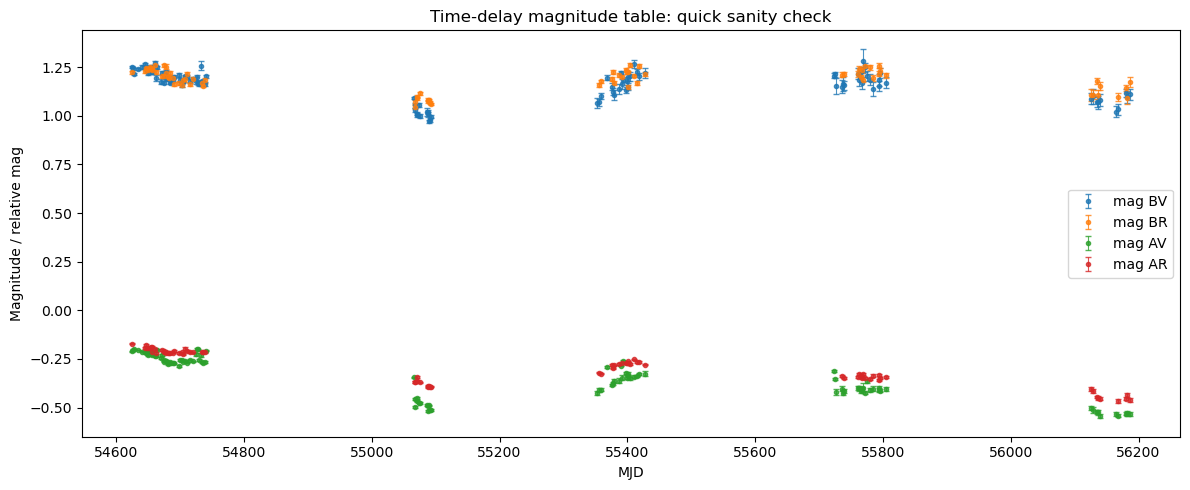

In [32]:
# Quick check for the time-delay magnitude table provided by user
mag_table_path = PROJECT_ROOT / 'Skyfield/scripts/time_delay_magnitudes.csv'
mag_table_df = pd.read_csv(mag_table_path)

for col in ['mag_AV', 'sigma_A_V', 'mag_BV', 'sigma_B_V', 'mag_AR', 'sigma_A_R', 'mag_BR', 'sigma_B_R', 'MJD']:
    if col in mag_table_df.columns:
        mag_table_df[col] = pd.to_numeric(mag_table_df[col], errors='coerce')

print('Loaded:', mag_table_path)
print('Rows:', len(mag_table_df))
print('Finite MJD rows:', mag_table_df['MJD'].notna().sum())
display(mag_table_df.head())

plot_df = mag_table_df.dropna(subset=['MJD']).copy()

plt.figure(figsize=(12, 5))
for mag_col, err_col, label in [
    ('mag_BV', 'sigma_B_V', 'mag BV'),
    ('mag_BR', 'sigma_B_R', 'mag BR'),
    ('mag_AV', 'sigma_A_V', 'mag AV'),
    ('mag_AR', 'sigma_A_R', 'mag AR'),
]:
    subset = plot_df.dropna(subset=[mag_col]).copy()
    if subset.empty:
        continue
    yerr = subset[err_col] if err_col in subset.columns else None
    plt.errorbar(
        subset['MJD'],
        subset[mag_col],
        yerr=yerr,
        fmt='o',
        markersize=3,
        linewidth=0.8,
        capsize=2,
        alpha=0.8,
        label=label,
    )

plt.xlabel('MJD')
plt.ylabel('Magnitude / relative mag')
plt.title('Time-delay magnitude table: quick sanity check')
plt.legend()
plt.tight_layout()
plt.show()

In [43]:
# Add chile time to mag_table_df
# MJD is days since 1858-11-17, so unit='D' + origin fixes the 1969/1970 offset.
mag_table_df['chile_time'] = pd.to_datetime(
    mag_table_df['MJD'],
    unit='D',
    origin='1858-11-17',
    utc=True,
).dt.tz_convert('America/Santiago')

mag_table_df[['MJD', 'chile_time']].head()

,MJD,chile_time
0,54624.4,2008-06-07 05:36:00.000000129-04:00
1,54626.4,2008-06-09 05:36:00.000000129-04:00
2,54628.4,2008-06-11 05:36:00.000000129-04:00
3,54633.4,2008-06-16 05:36:00.000000129-04:00
4,54640.4,2008-06-23 05:36:00.000000129-04:00


In [34]:
tdl_df = pd.read_json('/grad/a.saricaoglu/Downloads/time_delay_lenses.json')

# Filter to rows with valid coordinates in both DataFrames
valid_left = sled_df.dropna(subset=["RA", "DEC"])
valid_right = tdl_df.dropna(subset=["ra", "dec"])

print(f"Matching {len(valid_left)} left rows with {len(valid_right)} right rows")
print(f"Left NaN count: {sled_df[['RA', 'DEC']].isna().sum().sum()}")
print(f"Right NaN count: {tdl_df[['ra', 'dec']].isna().sum().sum()}")

sled_tdl_df = coordinate_match(
    valid_left,
    valid_right,
    left_ra="RA",
    left_dec="DEC",
    right_ra="ra",
    right_dec="dec",
    tolerance_arcsec=1.0,
    right_prefix="tdl",
    right_name="name",
    extra = ["catalog"]
)
print('Matched number of systems', np.sum(sled_tdl_df['tdl_matched'] == True) )

Matching 13025 left rows with 42 right rows
Left NaN count: 0
Right NaN count: 0
Matched number of systems 26


In [35]:
jwst_df = pd.read_csv('/grad/a.saricaoglu/Downloads/time_delay_cosmo_lenses.csv')

# Filter to rows with valid coordinates in both DataFrames
valid_left = sled_df.dropna(subset=["RA", "DEC"])
valid_right = jwst_df.dropna(subset=["s_ra", "s_dec"])

print(f"Matching {len(valid_left)} left rows with {len(valid_right)} right rows")
print(f"Left NaN count: {sled_df[['RA', 'DEC']].isna().sum().sum()}")
print(f"Right NaN count: {jwst_df[["s_ra", "s_dec"]].isna().sum().sum()}")

sled_jwst_df = coordinate_match(
    valid_left,
    valid_right,
    left_ra="RA",
    left_dec="DEC",
    right_ra="s_ra",
    right_dec="s_dec",
    tolerance_arcsec=1.0,
    right_prefix="jwst_tdl",
    right_name="target_name",
)
print('Matched number of systems', np.sum(sled_jwst_df['jwst_tdl_matched'] == True) )

Matching 13025 left rows with 80 right rows
Left NaN count: 0
Right NaN count: 0
Matched number of systems 4


In [36]:
desi_df = pd.read_csv('/grad/a.saricaoglu/Downloads/DESI_Single_Fiber_Lens_Search_I_watchlist_original.csv')

valid_left = sled_df.dropna(subset=["RA", "DEC"])
valid_right = desi_df.dropna(subset=["RA", "DEC"])

print(f"Matching {len(valid_left)} left rows with {len(valid_right)} right rows")
print(f"Left NaN count: {sled_df[['RA', 'DEC']].isna().sum().sum()}")
print(f"Right NaN count: {desi_df[['RA', 'DEC']].isna().sum().sum()}")

sled_desi_df = coordinate_match(
    valid_left,
    valid_right,
    left_ra="RA",
    left_dec="DEC",
    right_ra="RA",
    right_dec="DEC",
    tolerance_arcsec=1.0,
    right_prefix="desi",
    right_name="desi_name",
)
print('Matched number of systems', np.sum(sled_desi_df['desi_matched'] == True) )

valid_left = sled_matched_df.dropna(subset=["target_ra", "target_dec"])
valid_right = desi_df.dropna(subset=["RA", "DEC"])

print(f"Matching {len(valid_left)} left rows with {len(valid_right)} right rows")
print(f"Left NaN count: {sled_matched_df[['target_ra', 'target_dec']].isna().sum().sum()}")
print(f"Right NaN count: {desi_df[['RA', 'DEC']].isna().sum().sum()}")

sled_desi_matched_df = coordinate_match(
    valid_left,
    valid_right,
    left_ra="target_ra",
    left_dec="target_dec",
    right_ra="RA",
    right_dec="DEC",
    tolerance_arcsec=1.0,
    right_prefix="desi",
    right_name="desi_name",
)
print('Matched number of systems', np.sum(sled_desi_matched_df['desi_matched'] == True) )


Matching 13025 left rows with 4110 right rows
Left NaN count: 0
Right NaN count: 0
Matched number of systems 127
Matching 726 left rows with 4110 right rows
Left NaN count: 0
Right NaN count: 0
Matched number of systems 3


In [37]:
castles_sled_df = coordinate_match(
    left_df=sled_df.dropna(subset=["RA", "DEC"]),
    right_df=castles_df.dropna(subset=["RA", "DEC"]),
    left_ra="RA",
    left_dec="DEC",
    right_ra="RA",
    right_dec="DEC",
    tolerance_arcsec=1.0,
    right_prefix="castles",
    right_name="target_name",

)
print('Matched number of systems', np.sum(castles_sled_df['castles_matched'] == True) )

castles_sled_matched_df = coordinate_match(
    left_df=sled_matched_df.dropna(subset=["target_ra", "target_dec"]),
    right_df=castles_df.dropna(subset=["RA", "DEC"]),
    left_ra="target_ra",
    left_dec="target_dec",
    right_ra="RA",
    right_dec="DEC",
    tolerance_arcsec=1.0,
    right_prefix="castles",
    right_name="target_name"
)
print('Matched number of systems', np.sum(castles_sled_matched_df['castles_matched'] == True) )

Matched number of systems 5
Matched number of systems 1


In [38]:
# Create a csv file with systems that are not in SLED lenses

# Castles lenses that are not in SLED lenses
castles_only_mask = ~castles_df['target_name'].isin(
    [row['castles_target_name'] for _, row in castles_sled_df.iterrows() if row['castles_matched'] == True]
)
castles_only_df = castles_df.loc[castles_only_mask].copy()
print('Castles lenses not in SLED lenses:', len(castles_only_df))
castles_only_df['survey'] = 'Castles'

# Desi lenses that are not in SLED lenses
desi_only_mask = ~desi_df['desi_name'].isin(
    [row['desi_desi_name'] for _, row in sled_desi_matched_df.iterrows() if row['desi_matched'] == True]
)
desi_only_df = desi_df.loc[desi_only_mask].copy()
print('DESI lenses not in SLED lenses:', len(desi_only_df))
desi_only_df = desi_only_df.rename(columns={'desi_name': 'target_name'})
desi_only_df['survey'] = 'DESI'

# JWST TDL lenses that are not in SLED lenses
jwst_only_mask = ~jwst_df['target_name'].isin(
    [row['jwst_tdl_target_name'] for _, row in sled_jwst_df.iterrows() if row['jwst_tdl_matched'] == True]
)
jwst_only_df = jwst_df.loc[jwst_only_mask].copy()
print('JWST TDL lenses not in SLED lenses:', len(jwst_only_df))
jwst_only_df = jwst_only_df.rename(columns={'target_name': 'target_name', 's_ra': 'RA', 's_dec': 'DEC'})
jwst_only_df['survey'] = 'JWST'

# TDL lenses that are not in SLED lenses
tdl_only_mask = ~tdl_df['name'].isin(
    [row['tdl_name'] for _, row in sled_tdl_df.iterrows() if row['tdl_matched'] == True]
)
tdl_only_df = tdl_df.loc[tdl_only_mask].copy()
print('TDL lenses not in SLED lenses:', len(tdl_only_df))
tdl_only_df = tdl_only_df.rename(columns={'name': 'target_name', 'ra': 'RA', 'dec': 'DEC'})
tdl_only_df['survey'] = 'TDL'

# Create a CSV file with all lenses that are not in SLED lenses, merge names under 'target_name' column
all_not_in_sled_df = pd.concat([castles_only_df, desi_only_df, jwst_only_df, tdl_only_df], ignore_index=True)
# Drop duplicates based on 'target_name' and keep the first occurrence
all_not_in_sled_df = all_not_in_sled_df.drop_duplicates(subset=['target_name'], keep='first')

all_not_in_sled_df.to_csv('lenses_not_in_sled.csv', index=False)
print('Created lenses_not_in_sled.csv with', len(all_not_in_sled_df), 'lenses not in SLED lenses.')

Castles lenses not in SLED lenses: 64
DESI lenses not in SLED lenses: 4107
JWST TDL lenses not in SLED lenses: 23
TDL lenses not in SLED lenses: 16
Created lenses_not_in_sled.csv with 4167 lenses not in SLED lenses.


## 14. Export analysis products

In [39]:
exports = {
    "contamination_events.csv": contamination_analysis_df,
    "visit_summary.csv": visit_summary_df,
    "daily_contamination_summary.csv": daily_summary,
    "monthly_contamination_summary.csv": monthly_summary,
    "run_summary.csv": summary_df,
    "input_file_audit.csv": files_df,
    "possible_duplicate_events.csv": possible_duplicates,
}

for filename, frame in exports.items():
    path = ANALYSIS_DIR / filename
    frame.to_csv(path, index=False)
    print("Wrote:", path)

Wrote: /data/a.saricaoglu/repo/RubinsForge/Skyfield/files/cont_improvement_satchecker_final/analysis/contamination_events.csv
Wrote: /data/a.saricaoglu/repo/RubinsForge/Skyfield/files/cont_improvement_satchecker_final/analysis/visit_summary.csv
Wrote: /data/a.saricaoglu/repo/RubinsForge/Skyfield/files/cont_improvement_satchecker_final/analysis/daily_contamination_summary.csv
Wrote: /data/a.saricaoglu/repo/RubinsForge/Skyfield/files/cont_improvement_satchecker_final/analysis/monthly_contamination_summary.csv
Wrote: /data/a.saricaoglu/repo/RubinsForge/Skyfield/files/cont_improvement_satchecker_final/analysis/run_summary.csv
Wrote: /data/a.saricaoglu/repo/RubinsForge/Skyfield/files/cont_improvement_satchecker_final/analysis/input_file_audit.csv
Wrote: /data/a.saricaoglu/repo/RubinsForge/Skyfield/files/cont_improvement_satchecker_final/analysis/possible_duplicate_events.csv


## 15. Final validation checklist

Before interpreting population statistics, inspect:
1. `validation` for geometry-range failures.
2. contamination rows that fail the OpSim visit-target join.
3. `possible_duplicates` for adjacent-segment repeated detections.
4. a handful of individual contamination rows, comparing `Time`, `Event_Time`,
   `t_closest`, separation, sunlight, and brightness.
5. the simulation log for the same events.

No event is removed automatically by this notebook.

In [40]:
from skyfield.api import load, wgs84, S, W
eph = load('de421.bsp')
earth = eph['earth']
sun = eph['sun']
ts = load.timescale()
rubinobs_astr = earth +  wgs84.latlon(30.244633*S,  70.749417*W, elevation_m = 2647)
def sun_altitude_at_event(event_time):
    astro = rubinobs_astr.at(event_time).observe(sun)
    apparent = astro.apparent()
    alt, az, _ = apparent.altaz()
    return alt.degrees

def get_sun_altitude(timestamp):
    dt_utc = timestamp.to_pydatetime()
    ti = ts.from_datetime(dt_utc)

    apparent = rubinobs_astr.at(ti).observe(sun).apparent()
    alt, az, _ = apparent.altaz()

    return alt.degrees


contamination_analysis_df["sun_altitude_deg"] = (
    contamination_analysis_df["event_time"]
    .apply(get_sun_altitude)
)

contamination_analysis_df.groupby(
    ["event_month", "sunlit"]
)["sun_altitude_deg"].agg(
    ["count", "mean", "median", "min", "max"]
)

count       mean     median        min        max
event_month sunlit                                                   
2025-11     False      79 -26.927205 -27.541158 -31.884436 -19.585790
            True       42 -17.665294 -17.093066 -23.193961 -13.447063
2025-12     False      67 -24.723005 -24.108697 -31.284979 -18.677221
            True       40 -17.712000 -17.600128 -23.665722 -12.592946
2026-01     False      52 -26.128485 -27.071061 -32.320615 -17.924186
            True       79 -18.922241 -19.445708 -24.274470 -11.964148
2026-02     False      39 -25.958701 -25.634393 -31.155069 -19.352337
            True       71 -19.808585 -20.659252 -24.974163 -12.742860
2026-03     False      44 -26.804988 -27.465674 -31.873258 -20.364557
            True       31 -15.648522 -14.973845 -22.853335 -12.708659
2026-04     False      34 -30.882516 -31.406467 -37.025301 -18.306990
            True       36 -17.480398 -16.729940 -24.118905 -12.779334
2026-05     False      34 -24.902856 -25.501979 -30.801572 -19.210021
            True       36 -17.266357 -18.755807 -22.536577 -12.031066
2026-06     False      14 -25.043118 -23.885691 -28.929344 -22.723602
            True       56 -18.857200 -19.440487 -24.111200 -12.235454